# archon-emu
## Emulator / Debugger library for Archon Timing scripts
---
Dan Weatherill

University of Oxford

** Jan 17 2017 SAWG Meeting **

# Basic Details

* Written in pure Python with only pure python external dependencies (therefore it is **SLOW** but easy to get running)
* Python 3 **ONLY** (not deliberately broken on 2.7, but no testing and likely invalid constructs)
* Currently almost no nice UI, but can be used for various tasks. I have been using it for
    * development of timing scripts
    * easily viewing timing script from .acf file
    * converting legacy DSP timing scripts to Archon
* Still issues to work out and nice interfaces to make. Please send suggestions/ requests/ (ideally) pull requests  to **daniel.weatherill@physics.ox.ac.uk** and on github issues :-)

 __Available at: <https://github.com/LSSTDESC/archon_emu> __

# Features
1. Load and parse an .acf file into "nice" Python datastructures (`ArchonConfig` class)
2. Parse timing script and assemble a list of time parallel instructions that the timing cores will execute (`ArchonCompiler` class)
3. Step through these instructions and produce a list of states that will be output by timing cores (`ArchonVM` class), optionally with instrumentation showing what subroutine you are in and where it was called from (`ArchonVM_Instrumented` class)
4. Given the list of timing states, extract clock level information (`ArchonSM` class)


# Caveat Emptor

- This was developed for my own personal use and likely has many areas where it's bad or broken
- I am likely to update this and break it without telling people, keep track of the hash of the commit you're using
- There are a lot of things I can think of to put in this, but not enough spare time to do them all
- I've started writing some docstrings, but I have by no means finished!


# Points to Note
* Some things about the specification of Archon timing are actually not well specified by Archon manual (i.e. these constructs are never mentioned but have been seen in the wild so they must work!). I had to implement most of these so the program would work with the files sent by Paul O'Connor. Quiz:
    * What does this line do?
    
    ```
    StateA; IF MyParameter StateB
    ```
    
    * Or this one?
    
    ``` 
    IF MyParameter MyParameter-- 
    ```
    
    * Is this even a valid construct (It works in archon-emu)?
    ```
    StateA; CALL MySub(MyParameter); MyParameter--
    ```
    
    * This IS a valid construct but not mentioned in Archon manual
    ```
    MyParameter=623 #this is an end of line comment!
    ```
    

# Basic Usage
## installation
use pip or setuptools, i.e.

```
pip install -r requirements.txt
pip install -e .
```

## imports and setup

In [1]:
import warnings 
import importlib
import logging
from archon_emu.acffile import ArchonConfig, StateConfigWarning #.acf parsing
from archon_emu.archon_timing_dsl import ArchonCompiler #compile timing scripts
from archon_emu.archonVM import ArchonVM, ArchonVM_Instrumented #step through timing
#ArchonSM 

#set to logging.DEBUG to see a lot of stuff about compilation
importlib.reload(logging)
logging.basicConfig(level=logging.WARN)    

#you want to disable this warning or it will produce many 
#warnings for a lot of scripts
warnings.simplefilter('ignore',category=StateConfigWarning) 


## load and compile timing information

In [2]:
fl2 = 'seqs/CCD250_e2v_Image.acf'
#load and parse acf file
archon_conf = ArchonConfig.from_filename(fl2)
#compile timing file - can be customized in many ways if desired
compiler = ArchonCompiler.from_archonconfig(archon_conf)
#create a VM to step through timing states
vm  = ArchonVM.from_compiler(compiler)

module, constant, parameter and timing state information is available through property calls on the `ArchonConfig` object, for example:

In [3]:
print(archon_conf.parameters)
#print(archon_conf.constants)
#print(archon_conf.states)
#print(archon_conf.modules)

{'LCLK': 0, 'Tsr3': 10, 'Tsr7': 42, 'Tsr5': 4, 'Tsr1': 0, 'Tsrf5': 8, 'PixPre': 10, 'Expo': 1, 'Tsr8': 7, 'RowSkip': 0, 'Twait': 0, 'Light': 1, 'Tsf': 60, 'ExpTime': 0, 'Tnpc': 29, 'Tsr2': 10, 'Tpb': 400, 'WaiTime': 100, 'Tsr4': 10, 'Tsrf8': 14, 'RowRead1': 2048, 'Tsrf9': 102, 'PixSkip': 0, 'Tpc': 500, 'ReadDel': 0, 'RowRead2': 0, 'Tsrf7': 84, 'Tpu': 200, 'Npump': 0, 'Tsrf1': 1, 'Nclear': 2002, 'Tsrf6': 14, 'Tpa': 250, 'Nexpo': 100000, 'Tsrf3': 20, 'RowOver': 0, 'Tsrf4': 20, 'Tsr9': 51, 'Tsrf2': 20, 'PixRead': 576, 'Tsr6': 7, 'Tnpcf': 69, 'PixOver': 0, 'Pdepth': 1}


In [16]:
#properly organised timing script is also available, which can be useful if only provided with an .acf file
print(archon_conf.timing_script)

Start:
LowCLK; IF !LCLK GOTO Start
IDLE; CALL RCLR(4)
KEEPER; CALL EXPOSE(Expo)
KEEPER; CALL READOUT(Expo)
KEEPER; IF !Nexpo CALL ExpoDONE
KEEPER; GOTO Start
ExpoDONE:
KEEPER; Expo--
KEEPER; RETURN ExpoDONE
RCLR:
IDLE; CALL FCLR(Nclear)
KEEPER; CALL SCLR(PixSkip)
KEEPER; CALL SCLR(PixRead)
KEEPER; CALL SCLR(PixOver)
KEEPER; RETURN RCLR
FCLR:
PFA; PFA(Tpa)
PFB; PFB(Tpb)
PFC; PFC(Tpb)
PFD; PFD(Tpb)
PFE; PFE(Tpb)
PFF; PFF(Tpb)
PFG; PFG(Tpb)
PFH; PFH(Tpb)
PFI; PFI(Tpa)
KEEPER; RETURN FCLR
SCLR:
SF1;SF1(Tsf)
SF2;SF2(Tsf)
SF3;SF3(Tsf)
KEEPER; RETURN SCLR
EXPOSE:
KEEPER; IF Light OSHUT
KEEPER; CALL Integrate(ExpTime)
KEEPER; IF Light CSHUT
KEEPER; CALL Integrate(WaiTime)
KEEPER; RETURN EXPOSE
Integrate:
KEEPER; CALL IntFlush(275)
KEEPER; RETURN Integrate
IntFlush:
SR1;SR1(Tsrf1)
SR2;SR2(Tsrf2)
SR3;SR3(Tsrf3)
SR4;SR4(Tsrf4)
SR5;SR5(Tsrf5)
KEEPER
KEEPER;KEEPER(Tnpcf)
SR6;SR6(Tsrf6)
SR7;SR7(Tsrf7)
SR8;SR8(Tsrf8)
SR9;SR9(Tsrf9)
KEEPER; RETURN IntFlush
READOUT:
KEEPER; IF Npump CALL PUMP(Npump)
KE

Internally when we compile a timing script we get a list of lists, which represents instructions that happen at the same time. The CALL/GOTO/RETURN location targets are de-referenced and also the constant values

In [5]:
dsl_expr = compiler.construct_parser()
a = dsl_expr.parseString(compiler.tscript)

instructions = compiler.compile_timing_script()
print(instructions[:5])

[[[<ArchonInstructions.STATE: 0>, 'LowCLK'], [<ArchonInstructions.CONDITIONAL: 5>, False, 'LCLK'], [<ArchonInstructions.GOTO: 1>, 0]], [[<ArchonInstructions.STATE: 0>, 'IDLE'], [<ArchonInstructions.CALL: 2>, 8, 4]], [[<ArchonInstructions.STATE: 0>, 'KEEPER'], [<ArchonInstructions.CALL: 2>, 27, 'Expo']], [[<ArchonInstructions.STATE: 0>, 'KEEPER'], [<ArchonInstructions.CALL: 2>, 46, 'Expo']], [[<ArchonInstructions.STATE: 0>, 'KEEPER'], [<ArchonInstructions.CONDITIONAL: 5>, False, 'Nexpo'], [<ArchonInstructions.CALL: 2>, 6, 1]]]


# extracting state information
The `ArchonVM` class works using generator objects, so you can easily intervene and perform actions at any point in the timing you desire


In [6]:
#this gives us a generator expression
gen = vm.run()
#step through it like any other generator to get a sequnce of (time,instruction,statename) output by the timing cores
#each step is one archon core time step
for i in range(2):
    print(next(gen))

(0, 0, 'LowCLK')
(1, 0, 'LowCLK')


In [7]:
#nothing's happening!! Let's look at the debug output 
#need to use importlib.reload if in jupyter notebook or console
importlib.reload(logging)
vm.logger.setLevel(logging.DEBUG)
next(gen)
vm.logger.setLevel(logging.WARNING)

DEBUG:archon_emu.ArchonVM:iptr 0: setting state LowCLK
DEBUG:archon_emu.ArchonVM:iptr 0: CONDITIONAL on LCLK
DEBUG:archon_emu.ArchonVM:iptr 0: GOTO: 0


In [8]:
#what's the current value of LCLK
print('value of LCLK is %d' % vm.parameters['LCLK'])
#lets set it to 1
vm.parameters['LCLK'] = 1
for i in range(6):
    print(next(gen))
#ok now it's working!

value of LCLK is 0
(3, 0, 'LowCLK')
(4, 1, 'IDLE')
(5, 8, 'IDLE')
(6, 13, 'PFA')
(7, 118, 'PFA')
(8, 118, 'PFA')


In [9]:
#can also query various internal state of the VM
print('iptr %d ' % vm.instruction_ptr)
print('loopcount %d' % vm.loopcount)
print('callstack %s' % str(vm.callstack))

#exhaust the current loop
for i in range(248):
    next(gen)
    
print('iptr %d ' % vm.instruction_ptr)
print('loopcount %d' % vm.loopcount)
print('callstack %s' % str(vm.callstack))


iptr 118 
loopcount 248
callstack [1, 8, 13]
iptr 118 
loopcount 0
callstack [1, 8]


# extracting clock values

**Archon timing states do not correspond directly to clock outputs!**
Since they have "keeps" (i.e. tri-state logic), another layer of logic is needed to actually see clock outputs.
This is implemented in the ArchonSM class

There is some pretty printing for states implemented, but they can be pretty complicated.
The clocks for each module are shown, along with whether they have "keeps" or not (a "keep" is indicated by the - character)

To work out clock values from states, we have the `ArchonSM` class. It takes a set of clockstate definitions, module definitions, constant definitions and a VM instance in its constructor (the VM instance is used to de-reference parameter values which can change during the run)

In [10]:
print(archon_conf.states['PE'])

{3: CLOCKState: CHANGES=[00000000], VALUES=[{None: '0'}], 4: BiasState: GPIO=[--------], 5: ADState: CLAMP=^, 6: ADState: CLAMP=^, 7: ADState: CLAMP=^, 8: ADState: CLAMP=^, 10: CLOCKState: CHANGES=[01234341], VALUES=[{'S_HIGH': '4', 'P_HIGH': '3', 'RG_LOW': '0', 'P_LOW': '1', 'S_LOW': '2'}], 11: CLOCKState: CHANGES=[01000000], VALUES=[{None: '0', 'CL_LOW': '1'}]}


In [11]:
from archon_emu.archonSM import ArchonSM, filterclocks
sm = ArchonSM(archon_conf.states,archon_conf.modules,archon_conf.constants,vm)

`ArchonSM` has a method called `clock()` which takes the generator from a VM and returns a generator that emits dictionaries whose key is the module position and whose value is the values of the clocks in that module

In [12]:
#setup some parameters to be a bit quicker
vm.parameters['LCLK'] = 1
vm.parameters['Nclear'] = 0
vm.parameters['PixSkip'] = 0
vm.parameters['Tpa'] = 0
vm.parameters['Tpb'] = 1

In [13]:
#might want two "copies" of the VM generator
from itertools import tee
vmgen,smgen = tee(vm.run()) 
clockgen = sm.clock(smgen)
for i in range(20): #let's watch what module 10's clocks do
    print(str(next(vmgen)[2]) + '\t' + str(next(clockgen)[10]))

LowCLK	[0, 0, 0.5, 0, 0.5, 0, 0.5, 0]
IDLE	[12, 0, 0.5, 9, 9.5, 9, 9.5, 0]
IDLE	[12, 0, 0.5, 9, 9.5, 9, 9.5, 0]
PFA	[12, 0, 9.5, 9, 9.5, 9, 9.5, 0]
PFA	[12, 0, 9.5, 9, 9.5, 9, 9.5, 0]
PFB	[12, 9, 9.5, 0, 9.5, 9, 9.5, 0]
PFB	[12, 9, 9.5, 0, 9.5, 9, 9.5, 0]
PFC	[12, 9, 9.5, 0, 9.5, 0, 9.5, 9]
PFC	[12, 9, 9.5, 0, 9.5, 0, 9.5, 9]
PFD	[12, 0, 9.5, 9, 9.5, 0, 9.5, 9]
PFD	[12, 0, 9.5, 9, 9.5, 0, 9.5, 9]
PFE	[0, 0, 9.5, 9, 9.5, 9, 9.5, 0]
PFE	[0, 0, 9.5, 9, 9.5, 9, 9.5, 0]
PFF	[0, 0, 9.5, 9, 9.5, 9, 9.5, 0]
PFF	[0, 0, 9.5, 9, 9.5, 9, 9.5, 0]
PFG	[0, 0, 9.5, 9, 9.5, 9, 9.5, 0]
PFG	[0, 0, 9.5, 9, 9.5, 9, 9.5, 0]
PFH	[0, 0, 9.5, 9, 9.5, 9, 9.5, 0]
PFH	[0, 0, 9.5, 9, 9.5, 9, 9.5, 0]
PFI	[0, 0, 9.5, 9, 9.5, 9, 9.5, 0]


a `filterclocks` generator is provided for convenience.
It can provide either a dictionary of selected clocks (based on a dictionary mask), or (using the `flat=True` argument) a flat list of selected clocks. In this case, the dictionary mask should be of type `collections.OrderedDict` otherwise the output order across different modules is random

In [14]:

#choose the clock values we're interested in (parallel clocks here)
from collections import OrderedDict
#use an OrderedDict to ensure filter gets modules in correct order
#put "True" when we want the clock in the output, and "False" otherwise
#--------------------------RG----P0---S0----P1---S1----P2----S2---P3----
spec = OrderedDict({10 : [False,True,False,True,False,True,False,True]})
clockgen = filterclocks(sm.clock(vm.run()),spec,flat=True)
for i in range(13):
    print(next(clockgen))

[0, 0, 0, 0]
[0, 9, 9, 0]
[0, 9, 9, 0]
[0, 9, 9, 0]
[0, 9, 9, 0]
[9, 0, 9, 0]
[9, 0, 9, 0]
[9, 0, 0, 9]
[9, 0, 0, 9]
[0, 9, 0, 9]
[0, 9, 0, 9]
[0, 9, 9, 0]
[0, 9, 9, 0]


A couple of basic plotting utilities are provided
** warning** a LOT more of these need to be written, but they are fairly simple to make

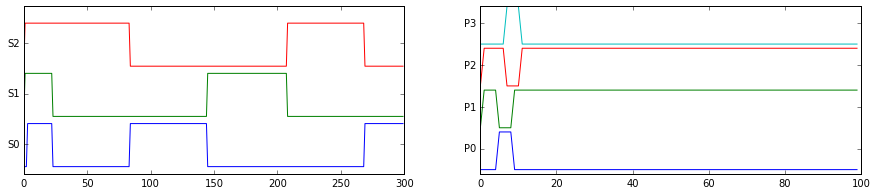

In [15]:
import matplotlib.pyplot as plt
%matplotlib inline
from archon_emu.plotting import simple_plot_clock_sequence
fig,ax  = plt.subplots(1,2,figsize=(15,3))
#let's filter on the serial clocks this time
#--------------------------------------------S0---------S1---------S2----------
serialspec = OrderedDict({10 : [False,False,True,False,True,False,True,False]})
clockgen = filterclocks(sm.clock(vm.run()),serialspec,flat=True)
labels = ['S0','S1','S2']
serialclocks = [next(clockgen) for _ in range(300)]
simple_plot_clock_sequence(ax[0],serialclocks,labels)

clockgen = filterclocks(sm.clock(vm.run()),spec,flat=True)
labels= ['P0','P1','P2','P3']
parclocks = [next(clockgen) for _ in range(100)]

simple_plot_clock_sequence(ax[1],parclocks,labels)


# Thanks for your time!

** daniel.weatherill@physics.ox.ac.uk **

<https://github.com/LSSTDESC/archon_emu>

